# Random walks: from molecular steps to diffusion

I follow 100,000 walkers. Each sweep gives every walker one unit step in a cardinal direction. pos contains unwrapped x and y positions. Mean-square displacement, MSD, is the mean squared distance from the starting point. Length is measured in lattice steps and time in sweeps. The corresponding diffusion coefficient is 1/4 in these units.

I develop this calculation in small steps. I run a cell, inspect its result and test it before adding the next part. Run the cells in order in Jupyter. A code cell defines a part of the calculation or carries it out; defining a function does not run it.

I permit free noncommercial teaching, learning and demonstrations with acknowledgment. Research and commercial use require my written permission. Earlier licensed releases retain their permissions. [Read the code-use terms](https://saswataiith.github.io/using-my-resources/).

Copyright (c) 2026 Saswata Bhattacharyya.

## Step 1: Prepare the Python environment

I install the packages listed in the next cell once in the same environment as the notebook. In Jupyter or Colab, remove the comment marker from the installation line below if a package is missing. NumPy stores arrays and evaluates numerical operations. Matplotlib displays plots. Pillow reads and writes images. This installation does not change the model parameters.

In [1]:
# %pip install numpy matplotlib
import numpy as np
assert np.isfinite(np.array([0.0, 1.0])).all()
print("NumPy is ready:", np.__version__)

NumPy is ready: 2.1.3


## Step 2: Input values

I retain the default values from the original calculation. The output name locates the files written by this notebook.

In [2]:
output = 'walkers-results'

## Step 3: Prepare the next part of the calculation

I define the following operations. These are the same operations as in the original source, written on separate lines so their order is clear. Inspect their values before running the next cell.

In [3]:
import sys
from pathlib import Path
import numpy as np

## Step 4: Prepare inputs and output locations

I name the input data and output directory explicitly. Re-running these cells replaces files in that lesson's output directory. I keep the original image or composition field separate from the evolving array.

In [4]:
out = Path(output)
out.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(7)
n = 100000
pos = np.zeros((n, 2), dtype=int)
dirs = np.array([[1, 0], [-1, 0], [0, 1], [0, -1]])
rows = []

## Step 5: Repeat the operation and inspect each case

I repeat the operation over the specified cases. Read the loop variable first, then follow what changes on each pass. The assertions check the stated numerical or topological condition.

In [5]:
for step in range(401):
    if step:
        pos += dirs[rng.integers(0, 4, n)]
    if step % 10 == 0:
        msd = np.mean(np.sum(pos * pos, axis=1))
        rows.append([step, msd, step])
        hist, _, _ = np.histogram2d(pos[:, 0], pos[:, 1], bins=256, range=[[-128, 128], [-128, 128]])
        np.savetxt(out / f'density_{step:04d}.csv', hist / n, delimiter=',')

## Step 6: My check of this result

I check finite values, conservation or the known reference result as specified below. An assertion stops the notebook if the condition fails. Inspect the quantities and tolerance rather than suppressing a failure.

In [6]:
np.savetxt(out / 'diagnostics.csv', rows, delimiter=',', header='steps,msd,theory', comments='')
assert abs(rows[-1][1] / 400 - 1) < 0.04
print('Walker MSD at 400 steps', rows[-1][1], 'theory 400')

Walker MSD at 400 steps 399.31192 theory 400


## Plot and interpret the result

I compare MSD with the number of sweeps. In these units the prediction is MSD=steps. Agreement concerns an ensemble, not an individual walker path. The density image is a normalized count per unit lattice bin.

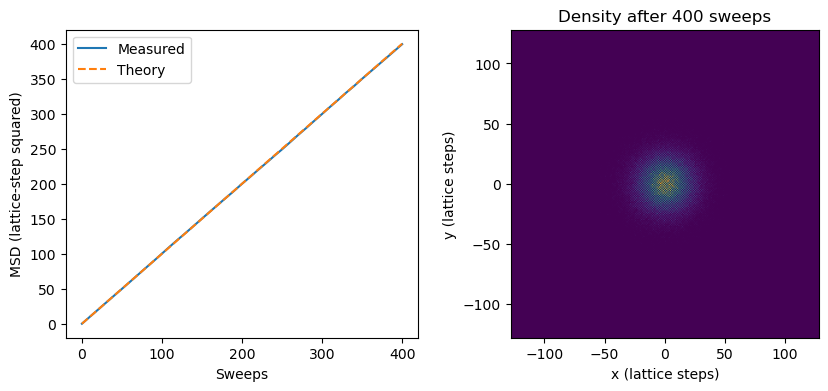

In [7]:
import matplotlib.pyplot as plt
records = np.asarray(rows)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(records[:, 0], records[:, 1], label="Measured")
axes[0].plot(records[:, 0], records[:, 2], "--", label="Theory")
axes[0].set_xlabel("Sweeps")
axes[0].set_ylabel("MSD (lattice-step squared)")
axes[0].legend()
axes[1].imshow(hist.T / n, origin="lower", extent=(-128, 128, -128, 128))
axes[1].set_title("Density after 400 sweeps")
axes[1].set_xlabel("x (lattice steps)")
axes[1].set_ylabel("y (lattice steps)")
plt.show()

## Step 7: Review and extend the calculation

I first restart the kernel and run all the required cells. Then I change one input, predict its effect and compare the result with that prediction. A successful check establishes the tested property; it does not establish convergence or equilibrium. I retain the [complete script](https://saswataiith.github.io/files/mesoscale/examples/walkers.py) for command-line use. The notebook embeds the calculation directly and does not need that script to run.